In [ ]:
from google.colab import files

uploaded = files.upload()

Saving gwl_tel_6_hourly_cgwb_ts_2021_2025.csv to gwl_tel_6_hourly_cgwb_ts_2021_2025.csv
Saving rainfall_tel_hr_telangana_sw_ts_2021_2025.csv to rainfall_tel_hr_telangana_sw_ts_2021_2025.csv
Saving rainfall_tel_hr_telangana_sw_ts_2026_2030.csv to rainfall_tel_hr_telangana_sw_ts_2026_2030.csv
Saving temprature_tel_hr_telangana_sw_ts_2021_2025.csv to temprature_tel_hr_telangana_sw_ts_2021_2025.csv
Saving temprature_tel_hr_telangana_sw_ts_2026_2030.csv to temprature_tel_hr_telangana_sw_ts_2026_2030.csv


In [ ]:
import pandas as pd

rain1 = pd.read_csv("rainfall_tel_hr_telangana_sw_ts_2021_2025.csv")
rain2 = pd.read_csv("rainfall_tel_hr_telangana_sw_ts_2026_2030.csv")

gwl = pd.read_csv("gwl_tel_6_hourly_cgwb_ts_2021_2025.csv")

temp1 = pd.read_csv("temprature_tel_hr_telangana_sw_ts_2021_2025.csv")
temp2 = pd.read_csv("temprature_tel_hr_telangana_sw_ts_2026_2030.csv")

print("Files loaded successfully!")

Files loaded successfully!


In [ ]:
import os

print(os.listdir())

['.config', 'rainfall_tel_hr_telangana_sw_ts_2026_2030.csv', 'temprature_tel_hr_telangana_sw_ts_2021_2025.csv', 'gwl_tel_6_hourly_cgwb_ts_2021_2025.csv', 'rainfall_tel_hr_telangana_sw_ts_2021_2025.csv', 'temprature_tel_hr_telangana_sw_ts_2026_2030.csv', 'sample_data']


In [ ]:
!pip install -q xgboost

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import accuracy_score

In [ ]:
rain1 = pd.read_csv("rainfall_tel_hr_telangana_sw_ts_2021_2025.csv")
rain2 = pd.read_csv("rainfall_tel_hr_telangana_sw_ts_2026_2030.csv")

temp1 = pd.read_csv("temprature_tel_hr_telangana_sw_ts_2021_2025.csv")
temp2 = pd.read_csv("temprature_tel_hr_telangana_sw_ts_2026_2030.csv")

gwl = pd.read_csv("gwl_tel_6_hourly_cgwb_ts_2021_2025.csv")

print("Files Loaded Successfully")

Files Loaded Successfully


In [ ]:
print(rain1.columns)

print("\n")

print(temp1.columns)

print("\n")

print(gwl.columns)

Index(['SlNo', 'Station', 'Agency', 'State LGD Code', 'State',
       'District LGD Code', 'District', 'Tehsil', 'Block', 'Village', 'River',
       'Basin', 'Tributary', 'Subtributary', 'SubSubtributary', 'Local River',
       'Latitude', 'Longitude', 'Data Acquisition Time',
       'Telemetry Hourly Rainfall (mm)'],
      dtype='object')


Index(['SlNo', 'Station', 'Agency', 'State LGD Code', 'State',
       'District LGD Code', 'District', 'Tehsil', 'Block', 'Village', 'River',
       'Basin', 'Tributary', 'Subtributary', 'SubSubtributary', 'Local River',
       'Latitude', 'Longitude', 'Data Acquisition Time',
       'Air Temperature Telemetry Hourly (ºC)'],
      dtype='object')


Index(['SlNo', 'Station', 'Agency', 'State LGD Code', 'State',
       'District LGD Code', 'District', 'Tehsil', 'Block', 'Village', 'River',
       'Basin', 'Tributary', 'Subtributary', 'SubSubtributary', 'Local River',
       'Latitude', 'Longitude', 'RL_MSL', 'Data Acquisition Time',
       'Groundwat

In [ ]:
rain = pd.concat([rain1, rain2], ignore_index=True)

In [ ]:
import pandas as pd

rain1 = pd.read_csv("rainfall_tel_hr_telangana_sw_ts_2021_2025.csv")
rain2 = pd.read_csv("rainfall_tel_hr_telangana_sw_ts_2026_2030.csv")

temp1 = pd.read_csv("temprature_tel_hr_telangana_sw_ts_2021_2025.csv")
temp2 = pd.read_csv("temprature_tel_hr_telangana_sw_ts_2026_2030.csv")

gwl = pd.read_csv("gwl_tel_6_hourly_cgwb_ts_2021_2025.csv")

print("Files Loaded Successfully")

Files Loaded Successfully


In [ ]:
rain = pd.concat([rain1, rain2], ignore_index=True)

temp = pd.concat([temp1, temp2], ignore_index=True)

print("Rain Shape:", rain.shape)
print("Temp Shape:", temp.shape)
print("GWL Shape:", gwl.shape)

Rain Shape: (75595, 20)
Temp Shape: (1104257, 20)
GWL Shape: (1779618, 21)


In [ ]:
rain = rain[
    ['District',
     'Data Acquisition Time',
     'Telemetry Hourly Rainfall (mm)']
]

rain.columns = [
    'District',
    'Date',
    'Rainfall'
]

In [ ]:
rain.head()

,District,Date,Rainfall
0,NALGONDA,06-11-2023 15:00,3.0
1,NALGONDA,06-11-2023 16:00,1.5
2,NALGONDA,06-11-2023 16:00,1.5
3,NALGONDA,08-11-2023 22:00,1.0
4,NALGONDA,08-11-2023 23:00,0.5


In [ ]:
temp = temp[
    ['District',
     'Data Acquisition Time',
     'Air Temperature Telemetry Hourly (ºC)']
]

temp.columns = [
    'District',
    'Date',
    'Temperature'
]

temp.head()

,District,Date,Temperature
0,NALGONDA,26-10-2023 16:00,60.0
1,NALGONDA,26-10-2023 20:00,23.4
2,NALGONDA,26-10-2023 21:00,22.5
3,NALGONDA,27-10-2023 00:00,20.4
4,NALGONDA,27-10-2023 01:00,20.5


In [ ]:
gwl = gwl[
    ['District',
     'Data Acquisition Time',
     'Groundwater Level Telemetry 6 Hourly (meter)']
]

gwl.columns = [
    'District',
    'Date',
    'Groundwater'
]

gwl.head()

,District,Date,Groundwater
0,NALGONDA,19-11-2023 12:00,-7.60
1,NALGONDA,19-11-2023 18:00,-9.35
2,NALGONDA,20-11-2023 00:00,-8.55
3,NALGONDA,20-11-2023 06:00,-8.52
4,NALGONDA,20-11-2023 12:00,-7.70


In [ ]:
rain['Date'] = pd.to_datetime(
    rain['Date'],
    format='%d-%m-%Y %H:%M',
    errors='coerce'
)

temp['Date'] = pd.to_datetime(
    temp['Date'],
    format='%d-%m-%Y %H:%M',
    errors='coerce'
)

gwl['Date'] = pd.to_datetime(
    gwl['Date'],
    format='%d-%m-%Y %H:%M',
    errors='coerce'
)

In [ ]:
rain = rain.drop_duplicates()
temp = temp.drop_duplicates()
gwl = gwl.drop_duplicates()

print("Rain:", rain.shape)
print("Temp:", temp.shape)
print("Groundwater:", gwl.shape)

Rain: (68375, 3)
Temp: (835318, 3)
Groundwater: (1769282, 3)


In [ ]:
rain['Day'] = rain['Date'].dt.date
temp['Day'] = temp['Date'].dt.date
gwl['Day'] = gwl['Date'].dt.date

In [ ]:
rain_daily = rain.groupby(
    ['District','Day']
)['Rainfall'].sum().reset_index()

rain_daily.head()

,District,Day,Rainfall
0,ADILABAD,2023-07-26,1.5
1,ADILABAD,2023-07-27,143.5
2,ADILABAD,2023-07-28,40.5
3,ADILABAD,2023-07-29,623.0
4,ADILABAD,2023-07-30,586.5


In [ ]:
temp_daily = temp.groupby(
    ['District','Day']
)['Temperature'].mean().reset_index()

temp_daily.head()

,District,Day,Temperature
0,ADILABAD,2023-07-25,29.022222
1,ADILABAD,2023-07-26,28.533333
2,ADILABAD,2023-07-27,26.970833
3,ADILABAD,2023-07-28,27.179167
4,ADILABAD,2023-07-29,27.804167


In [ ]:
gwl_daily = gwl.groupby(
    ['District','Day']
)['Groundwater'].mean().reset_index()

gwl_daily.head()

,District,Day,Groundwater
0,ADILABAD,2022-12-26,-11.763333
1,ADILABAD,2022-12-27,-11.830000
2,ADILABAD,2022-12-28,-11.830000
3,ADILABAD,2022-12-29,-11.837500
4,ADILABAD,2022-12-30,-11.847500


In [ ]:
rain_daily.head()

temp_daily.head()

gwl_daily.head()

,District,Day,Groundwater
0,ADILABAD,2022-12-26,-11.763333
1,ADILABAD,2022-12-27,-11.830000
2,ADILABAD,2022-12-28,-11.830000
3,ADILABAD,2022-12-29,-11.837500
4,ADILABAD,2022-12-30,-11.847500


In [ ]:
print("Rain Daily Shape:", rain_daily.shape)
print("Temp Daily Shape:", temp_daily.shape)
print("GWL Daily Shape:", gwl_daily.shape)

Rain Daily Shape: (9002, 3)
Temp Daily Shape: (20431, 3)
GWL Daily Shape: (35168, 3)


In [ ]:
df = rain_daily.merge(
    temp_daily,
    on=['District','Day'],
    how='inner'
)

df = df.merge(
    gwl_daily,
    on=['District','Day'],
    how='inner'
)

print(df.shape)
df.head()

(8130, 5)


,District,Day,Rainfall,Temperature,Groundwater
0,ADILABAD,2023-07-26,1.5,28.533333,-11.280909
1,ADILABAD,2023-07-27,143.5,26.970833,-11.073341
2,ADILABAD,2023-07-28,40.5,27.179167,-10.897773
3,ADILABAD,2023-07-29,623.0,27.804167,-11.082705
4,ADILABAD,2023-07-30,586.5,26.845833,-11.094409


In [ ]:
print(df.shape)
df.head()

(8130, 5)


,District,Day,Rainfall,Temperature,Groundwater
0,ADILABAD,2023-07-26,1.5,28.533333,-11.280909
1,ADILABAD,2023-07-27,143.5,26.970833,-11.073341
2,ADILABAD,2023-07-28,40.5,27.179167,-10.897773
3,ADILABAD,2023-07-29,623.0,27.804167,-11.082705
4,ADILABAD,2023-07-30,586.5,26.845833,-11.094409


In [ ]:
print(df['District'].nunique())

22


In [ ]:
df.describe()

,Rainfall,Temperature,Groundwater
count,8130.000000,8130.000000,8130.000000
mean,1459.552399,27.160021,-9.202500
std,2787.879640,3.225307,5.972420
min,0.500000,8.583333,-35.886250
25%,6.000000,25.429484,-11.503870
50%,296.250000,27.212500,-8.260677
75%,1382.375000,29.007332,-5.433329
max,16006.500000,39.544444,20.090000


In [ ]:
# Normalize features

df['Rainfall_Norm'] = (
    df['Rainfall'].max() - df['Rainfall']
) / (
    df['Rainfall'].max() - df['Rainfall'].min()
)

df['Temp_Norm'] = (
    df['Temperature'] - df['Temperature'].min()
) / (
    df['Temperature'].max() - df['Temperature'].min()
)

df['Groundwater_Norm'] = (
    df['Groundwater'] - df['Groundwater'].min()
) / (
    df['Groundwater'].max() - df['Groundwater'].min()
)

In [ ]:
df['Scarcity_Score'] = (
      0.4 * df['Rainfall_Norm']
    + 0.3 * df['Temp_Norm']
    + 0.3 * df['Groundwater_Norm']
)

In [ ]:
def label(score):

    if score < 0.25:
        return "Low"

    elif score < 0.50:
        return "Medium"

    elif score < 0.75:
        return "High"

    else:
        return "Critical"

df['Risk'] = df['Scarcity_Score'].apply(label)

In [ ]:
df['Risk'].value_counts()

,count
Risk,
High,6223
Critical,1513
Medium,380
Low,14


In [ ]:
X = df[
[
    'Rainfall',
    'Temperature',
    'Groundwater'
]
]

y = df['Risk']

In [ ]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

y = encoder.fit_transform(y)

print(encoder.classes_)

['Critical' 'High' 'Low' 'Medium']


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

dt = DecisionTreeClassifier(
    random_state=42
)

dt.fit(X_train, y_train)

dt_pred = dt.predict(X_test)

dt_acc = accuracy_score(
    y_test,
    dt_pred
)

print("Decision Tree:", dt_acc)

Decision Tree: 0.9698646986469864


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

rf_acc = accuracy_score(
    y_test,
    rf_pred
)

print("Random Forest:", rf_acc)

Random Forest: 0.981549815498155


In [ ]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=100,
    random_state=42
)

xgb.fit(X_train, y_train)

xgb_pred = xgb.predict(X_test)

xgb_acc = accuracy_score(
    y_test,
    xgb_pred
)

print("XGBoost:", xgb_acc)

XGBoost: 0.9833948339483395


In [ ]:
results = pd.DataFrame({

    'Model':[
        'Decision Tree',
        'Random Forest',
        'XGBoost'
    ],

    'Accuracy':[
        dt_acc,
        rf_acc,
        xgb_acc
    ]

})

print(results)

           Model  Accuracy
0  Decision Tree  0.969865
1  Random Forest  0.981550
2        XGBoost  0.983395


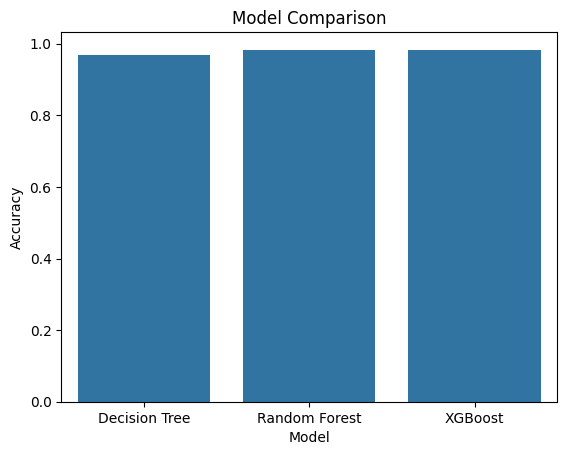

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.barplot(
    x='Model',
    y='Accuracy',
    data=results
)

plt.title(
    "Model Comparison"
)

plt.show()

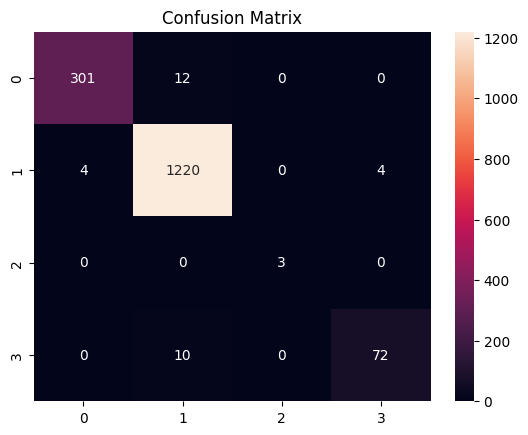

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    rf_pred
)

sns.heatmap(
    cm,
    annot=True,
    fmt='d'
)

plt.title(
    "Confusion Matrix"
)

plt.show()

In [ ]:
df['Risk'].value_counts()

,count
Risk,
High,6223
Critical,1513
Medium,380
Low,14


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    xgb_pred,
    target_names=encoder.classes_
))

              precision    recall  f1-score   support

    Critical       0.98      0.96      0.97       313
        High       0.99      0.99      0.99      1228
         Low       1.00      1.00      1.00         3
      Medium       0.94      0.93      0.93        82

    accuracy                           0.98      1626
   macro avg       0.98      0.97      0.97      1626
weighted avg       0.98      0.98      0.98      1626



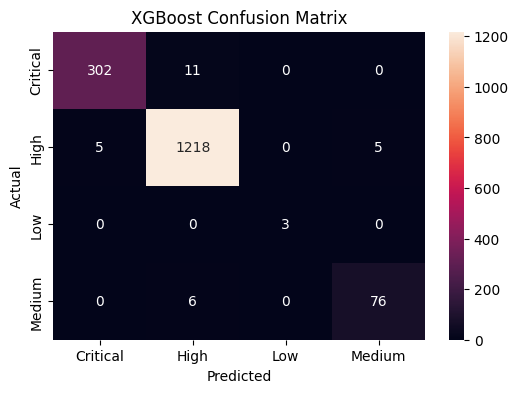

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt


cm = confusion_matrix(
    y_test,
    xgb_pred
)


plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("XGBoost Confusion Matrix")

plt.show()

In [ ]:
importance = pd.DataFrame({

    'Feature': X.columns,
    'Importance': xgb.feature_importances_

})


importance = importance.sort_values(
    by='Importance',
    ascending=False
)


importance

,Feature,Importance
0,Rainfall,0.448747
1,Temperature,0.284511
2,Groundwater,0.266742


In [ ]:
df['District'].unique()

array(['ADILABAD', 'BHADRADRI', 'BHUPALPALLY', 'JOGULAMBA(GADWAL)',
       'KAMAREDDY', 'KARIMNAGAR', 'KHAMMAM', 'KUMURAM BHEEM',
       'MAHBUBNAGAR', 'MANCHERIAL', 'MEDAK', 'MULUGU', 'NAGARKURNOOL',
       'NALGONDA', 'NARAYANPET', 'NIRMAL', 'PEDDAPALLY',
       'RAJANNA SIRCILLA', 'SANGA REDDY', 'SIDDIPET', 'VIKARABAD',
       'WANAPARTHY'], dtype=object)

In [ ]:
hyderabad_data = df[
    df['District']=='HYDERABAD'
]

hyderabad_data.head()

,District,Day,Rainfall,Temperature,Groundwater,Rainfall_Norm,Temp_Norm,Groundwater_Norm,Scarcity_Score,Risk


In [ ]:
rain['District'].unique()

array(['NALGONDA', 'BHUPALPALLY', 'BHADRADRI', 'MANCHERIAL',
       'NAGARKURNOOL', 'JOGULAMBA(GADWAL)', 'NIRMAL', 'MAHBUBNAGAR',
       'KUMURAM BHEEM', 'SIDDIPET', 'VIKARABAD', 'MULUGU', 'KHAMMAM',
       'KARIMNAGAR', 'ADILABAD', 'RAJANNA SIRCILLA', 'KAMAREDDY', 'MEDAK',
       'NARAYANPET', 'SANGA REDDY', 'WANAPARTHY', 'PEDDAPALLY'],
      dtype=object)

In [ ]:
print(rain.columns)

Index(['District', 'Date', 'Rainfall', 'Day'], dtype='object')


In [ ]:
rain_original = pd.concat(
    [rain1, rain2],
    ignore_index=True
)

print(rain_original.columns)

Index(['SlNo', 'Station', 'Agency', 'State LGD Code', 'State',
       'District LGD Code', 'District', 'Tehsil', 'Block', 'Village', 'River',
       'Basin', 'Tributary', 'Subtributary', 'SubSubtributary', 'Local River',
       'Latitude', 'Longitude', 'Data Acquisition Time',
       'Telemetry Hourly Rainfall (mm)'],
      dtype='object')


In [ ]:
rain_original[['Station',
               'District',
               'Village',
               'Latitude',
               'Longitude']].head(20)

,Station,District,Village,Latitude,Longitude
0,AKBR,NALGONDA,-,16.697,79.089
1,AKBR,NALGONDA,-,16.697,79.089
2,AKBR,NALGONDA,-,16.697,79.089
3,AKBR,NALGONDA,-,16.697,79.089
4,AKBR,NALGONDA,-,16.697,79.089
5,AKBR,NALGONDA,-,16.697,79.089
6,AKBR,NALGONDA,-,16.697,79.089
7,AKBR,NALGONDA,-,16.697,79.089
8,AKBR,NALGONDA,-,16.697,79.089
9,AKBR,NALGONDA,-,16.697,79.089


In [ ]:
rain_original[
    rain_original['District'].str.contains(
        'HYD',
        case=False,
        na=False
    )
][['Station','District','Village','Latitude','Longitude']].head()

,Station,District,Village,Latitude,Longitude


In [ ]:
print(rain_original.columns)

Index(['SlNo', 'Station', 'Agency', 'State LGD Code', 'State',
       'District LGD Code', 'District', 'Tehsil', 'Block', 'Village', 'River',
       'Basin', 'Tributary', 'Subtributary', 'SubSubtributary', 'Local River',
       'Latitude', 'Longitude', 'Data Acquisition Time',
       'Telemetry Hourly Rainfall (mm)'],
      dtype='object')


In [ ]:
hyd_area = rain_original[
    (rain_original['Latitude'] >= 17.2) &
    (rain_original['Latitude'] <= 17.6) &
    (rain_original['Longitude'] >= 78.2) &
    (rain_original['Longitude'] <= 78.7)
]


hyd_area[['Station','District','Village','Latitude','Longitude']].drop_duplicates()

,Station,District,Village,Latitude,Longitude


In [ ]:
rain_original['Station'].nunique()

38

In [ ]:
rain_original[['Station','District','Latitude','Longitude']].drop_duplicates().head(50)

,Station,District,Latitude,Longitude
0,AKBR,NALGONDA,16.697,79.089
1101,Boggulawagu,BHUPALPALLY,18.583,79.857
5338,Dindi_2,NALGONDA,16.550,78.685
6180,Dummugudem,BHADRADRI,17.876,80.876
7049,Ghanpur Lake_1,BHUPALPALLY,18.308,79.872
10728,Gollavagu_1,MANCHERIAL,18.869,79.678
11598,Gudipally Gattu reservoir,NAGARKURNOOL,16.381,78.292
12192,Jonnalaboguda,NAGARKURNOOL,16.252,78.314
12917,Jurala Project,JOGULAMBA(GADWAL),16.323,77.706
13868,Kaddam project,NIRMAL,19.680,78.440


In [ ]:
df.head()

,District,Day,Rainfall,Temperature,Groundwater,Rainfall_Norm,Temp_Norm,Groundwater_Norm,Scarcity_Score,Risk
0,ADILABAD,2023-07-26,1.5,28.533333,-11.280909,0.999938,0.644357,0.439568,0.725152,High
1,ADILABAD,2023-07-27,143.5,26.970833,-11.073341,0.991066,0.593890,0.443276,0.707576,High
2,ADILABAD,2023-07-28,40.5,27.179167,-10.897773,0.997501,0.600619,0.446412,0.713110,High
3,ADILABAD,2023-07-29,623.0,27.804167,-11.082705,0.961108,0.620806,0.443108,0.703618,High
4,ADILABAD,2023-07-30,586.5,26.845833,-11.094409,0.963389,0.589853,0.442899,0.695181,High


In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df['District_encoded'] = le.fit_transform(df['District'])

In [ ]:
features = [
'Rainfall',
'Temperature',
'Groundwater',
'Latitude',
'Longitude',
'District_encoded'
]

In [ ]:
df.head()

,District,Day,Rainfall,Temperature,Groundwater,Rainfall_Norm,Temp_Norm,Groundwater_Norm,Scarcity_Score,Risk,District_encoded
0,ADILABAD,2023-07-26,1.5,28.533333,-11.280909,0.999938,0.644357,0.439568,0.725152,High,0
1,ADILABAD,2023-07-27,143.5,26.970833,-11.073341,0.991066,0.593890,0.443276,0.707576,High,0
2,ADILABAD,2023-07-28,40.5,27.179167,-10.897773,0.997501,0.600619,0.446412,0.713110,High,0
3,ADILABAD,2023-07-29,623.0,27.804167,-11.082705,0.961108,0.620806,0.443108,0.703618,High,0
4,ADILABAD,2023-07-30,586.5,26.845833,-11.094409,0.963389,0.589853,0.442899,0.695181,High,0


In [ ]:
location = rain_original[
    [
        'Station',
        'District',
        'Latitude',
        'Longitude'
    ]
].drop_duplicates()


location.head()

,Station,District,Latitude,Longitude
0,AKBR,NALGONDA,16.697,79.089
1101,Boggulawagu,BHUPALPALLY,18.583,79.857
5338,Dindi_2,NALGONDA,16.550,78.685
6180,Dummugudem,BHADRADRI,17.876,80.876
7049,Ghanpur Lake_1,BHUPALPALLY,18.308,79.872


In [ ]:
df

,District,Day,Rainfall,Temperature,Groundwater,Rainfall_Norm,Temp_Norm,Groundwater_Norm,Scarcity_Score,Risk,District_encoded
0,ADILABAD,2023-07-26,1.5,28.533333,-11.280909,0.999938,0.644357,0.439568,0.725152,High,0
1,ADILABAD,2023-07-27,143.5,26.970833,-11.073341,0.991066,0.593890,0.443276,0.707576,High,0
2,ADILABAD,2023-07-28,40.5,27.179167,-10.897773,0.997501,0.600619,0.446412,0.713110,High,0
3,ADILABAD,2023-07-29,623.0,27.804167,-11.082705,0.961108,0.620806,0.443108,0.703618,High,0
4,ADILABAD,2023-07-30,586.5,26.845833,-11.094409,0.963389,0.589853,0.442899,0.695181,High,0
...,...,...,...,...,...,...,...,...,...,...,...
8125,WANAPARTHY,2025-10-24,10.0,24.904167,-3.823000,0.999406,0.527140,0.572801,0.729745,High,21
8126,WANAPARTHY,2025-10-28,8.5,24.434783,-3.591150,0.999500,0.511979,0.576943,0.726477,High,21
8127,WANAPARTHY,2025-10-29,27.0,24.329167,-3.217325,0.998344,0.508568,0.583621,0.726995,High,21
8128,WANAPARTHY,2025-11-05,3.0,26.250000,-3.416306,0.999844,0.570608,0.580066,0.745140,High,21


In [ ]:
df = df.merge(
    location,
    on='District',
    how='left'
)

In [ ]:
df.head()

,District,Day,Rainfall,Temperature,Groundwater,Rainfall_Norm,Temp_Norm,Groundwater_Norm,Scarcity_Score,Risk,District_encoded,Station,Latitude,Longitude
0,ADILABAD,2023-07-26,1.5,28.533333,-11.280909,0.999938,0.644357,0.439568,0.725152,High,0,Mathadivagu Project,19.682,78.447
1,ADILABAD,2023-07-26,1.5,28.533333,-11.280909,0.999938,0.644357,0.439568,0.725152,High,0,Satnala project,19.644,78.664
2,ADILABAD,2023-07-27,143.5,26.970833,-11.073341,0.991066,0.593890,0.443276,0.707576,High,0,Mathadivagu Project,19.682,78.447
3,ADILABAD,2023-07-27,143.5,26.970833,-11.073341,0.991066,0.593890,0.443276,0.707576,High,0,Satnala project,19.644,78.664
4,ADILABAD,2023-07-28,40.5,27.179167,-10.897773,0.997501,0.600619,0.446412,0.713110,High,0,Mathadivagu Project,19.682,78.447


In [ ]:
from sklearn.preprocessing import LabelEncoder

district_encoder = LabelEncoder()

df['District_encoded'] = district_encoder.fit_transform(
    df['District']
)

In [ ]:
features = [

'Rainfall',
'Temperature',
'Groundwater',

'Latitude',
'Longitude',

'District_encoded'

]

In [ ]:
X = df[features]

y = df['Risk']

In [ ]:
from sklearn.model_selection import train_test_split


X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
from sklearn.tree import DecisionTreeClassifier


dt = DecisionTreeClassifier(
    random_state=42
)

dt.fit(
    X_train,
    y_train
)

dt_accuracy = dt.score(
    X_test,
    y_test
)

print("Decision Tree Accuracy:",dt_accuracy)

Decision Tree Accuracy: 0.9886326729457616


In [ ]:
from xgboost import XGBClassifier


xgb = XGBClassifier(
    n_estimators=200,
    random_state=42
)

# Ensure y_train and y_test are numerically encoded
y_train_encoded = encoder.transform(y_train)
y_test_encoded = encoder.transform(y_test)

xgb.fit(
    X_train,
    y_train_encoded
)


xgb_accuracy=xgb.score(
    X_test,
    y_test_encoded
)


print("XGBoost Accuracy:",xgb_accuracy)

XGBoost Accuracy: 0.9941539460863917


In [ ]:
importance = pd.DataFrame({

'Feature':features[:len(rf.feature_importances_)], # Ensure the feature list matches the length of importances

'Importance':rf.feature_importances_

})


importance.sort_values(
    by='Importance',
    ascending=False
)

,Feature,Importance
2,Groundwater,0.352089
1,Temperature,0.337310
0,Rainfall,0.310601


In [ ]:
location_data = df[
[
'Station',
'District',
'Latitude',
'Longitude'
]
].drop_duplicates()

location_data.head()

,Station,District,Latitude,Longitude
0,Mathadivagu Project,ADILABAD,19.682,78.447
1,Satnala project,ADILABAD,19.644,78.664
1338,Dummugudem,BHADRADRI,17.876,80.876
1339,Kinnerasani project,BHADRADRI,17.677,80.657
1874,Boggulawagu,BHUPALPALLY,18.583,79.857


In [ ]:
selected_location = "NALGONDA"


location_data[
location_data['District']==selected_location
]

,Station,District,Latitude,Longitude
10550,AKBR,NALGONDA,16.697,79.089
10551,Dindi_2,NALGONDA,16.550,78.685
10552,Nagarjuna Sagar_1,NALGONDA,16.575,79.311


In [ ]:
df['Day'] = pd.to_datetime(df['Day'])

In [ ]:
df.dtypes

,0
District,object
Day,datetime64[ns]
Rainfall,float64
Temperature,float64
Groundwater,float64
Rainfall_Norm,float64
Temp_Norm,float64
Groundwater_Norm,float64
Scarcity_Score,float64
Risk,object


In [ ]:
year_rainfall = df[
    df['District']=="NALGONDA"
]


year_rainfall.groupby(
    year_rainfall['Day'].dt.year
)['Rainfall'].mean()

,Rainfall
Day,
2023,9.766667
2024,44.687500
2025,21.638655


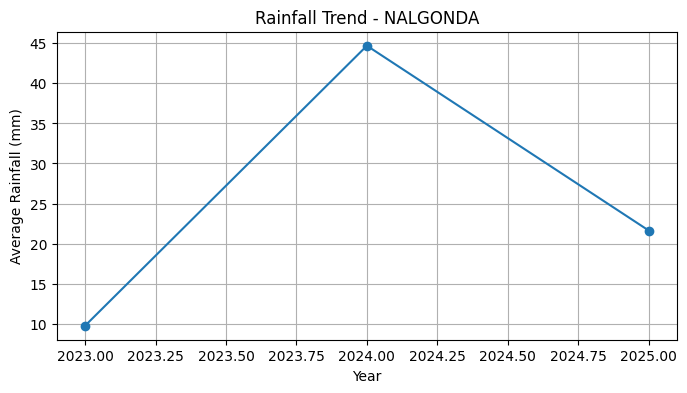

In [ ]:
import matplotlib.pyplot as plt

rain_trend = year_rainfall.groupby(
    year_rainfall['Day'].dt.year
)['Rainfall'].mean()


plt.figure(figsize=(8,4))

plt.plot(
    rain_trend.index,
    rain_trend.values,
    marker='o'
)

plt.title("Rainfall Trend - NALGONDA")
plt.xlabel("Year")
plt.ylabel("Average Rainfall (mm)")

plt.grid(True)

plt.show()

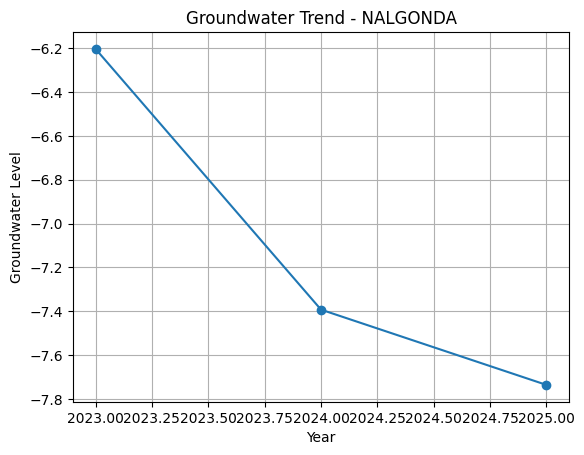

In [ ]:
groundwater_trend = year_rainfall.groupby(
    year_rainfall['Day'].dt.year
)['Groundwater'].mean()


groundwater_trend.plot(
    marker='o',
    title="Groundwater Trend - NALGONDA"
)

plt.xlabel("Year")
plt.ylabel("Groundwater Level")

plt.grid(True)

plt.show()

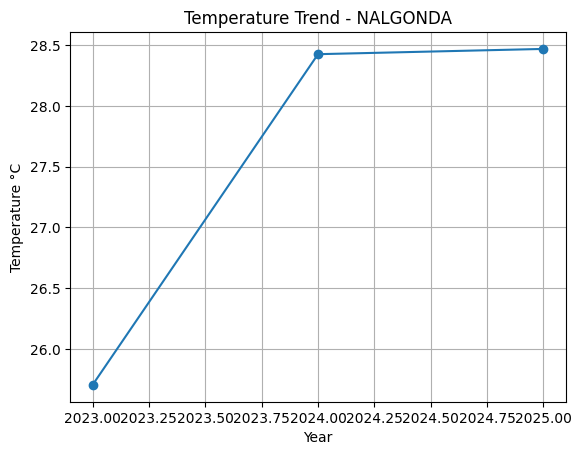

In [ ]:
temperature_trend = year_rainfall.groupby(
    year_rainfall['Day'].dt.year
)['Temperature'].mean()


temperature_trend.plot(
    marker='o',
    title="Temperature Trend - NALGONDA"
)

plt.xlabel("Year")
plt.ylabel("Temperature °C")

plt.grid(True)

plt.show()

In [ ]:
rain_original['District'].unique()

array(['NALGONDA', 'BHUPALPALLY', 'BHADRADRI', 'MANCHERIAL',
       'NAGARKURNOOL', 'JOGULAMBA(GADWAL)', 'NIRMAL', 'MAHBUBNAGAR',
       'KUMURAM BHEEM', 'SIDDIPET', 'VIKARABAD', 'MULUGU', 'KHAMMAM',
       'KARIMNAGAR', 'ADILABAD', 'RAJANNA SIRCILLA', 'KAMAREDDY', 'MEDAK',
       'NARAYANPET', 'SANGA REDDY', 'WANAPARTHY', 'PEDDAPALLY'],
      dtype=object)

In [ ]:
hyd_locations = [
    'HYDERABAD',
    'RANGAREDDY',
    'MEDCHAL MALKAJGIRI'
]


hyd_data = df[
    df['District'].isin(hyd_locations)
]


hyd_data.head()

,District,Day,Rainfall,Temperature,Groundwater,Rainfall_Norm,Temp_Norm,Groundwater_Norm,Scarcity_Score,Risk,District_encoded,Station,Latitude,Longitude


In [ ]:
hyd_data['District'].unique()

array([], dtype=object)

In [ ]:
df['Day'] = pd.to_datetime(df['Day'])

df['Year'] = df['Day'].dt.year

df.head()

,District,Day,Rainfall,Temperature,Groundwater,Rainfall_Norm,Temp_Norm,Groundwater_Norm,Scarcity_Score,Risk,District_encoded,Station,Latitude,Longitude,Year
0,ADILABAD,2023-07-26,1.5,28.533333,-11.280909,0.999938,0.644357,0.439568,0.725152,High,0,Mathadivagu Project,19.682,78.447,2023
1,ADILABAD,2023-07-26,1.5,28.533333,-11.280909,0.999938,0.644357,0.439568,0.725152,High,0,Satnala project,19.644,78.664,2023
2,ADILABAD,2023-07-27,143.5,26.970833,-11.073341,0.991066,0.593890,0.443276,0.707576,High,0,Mathadivagu Project,19.682,78.447,2023
3,ADILABAD,2023-07-27,143.5,26.970833,-11.073341,0.991066,0.593890,0.443276,0.707576,High,0,Satnala project,19.644,78.664,2023
4,ADILABAD,2023-07-28,40.5,27.179167,-10.897773,0.997501,0.600619,0.446412,0.713110,High,0,Mathadivagu Project,19.682,78.447,2023


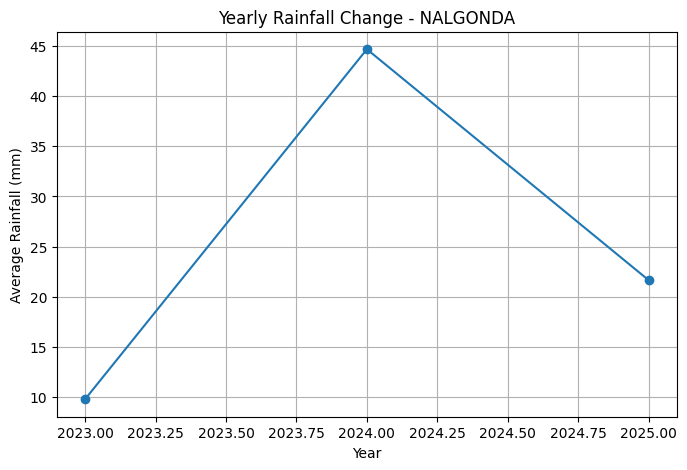

In [ ]:
import matplotlib.pyplot as plt


location = "NALGONDA"

temp = df[df['District']==location]


year_rain = temp.groupby('Year')['Rainfall'].mean()


plt.figure(figsize=(8,5))
plt.plot(year_rain.index,
         year_rain.values,
         marker='o')

plt.title(f"Yearly Rainfall Change - {location}")
plt.xlabel("Year")
plt.ylabel("Average Rainfall (mm)")
plt.grid()

plt.show()

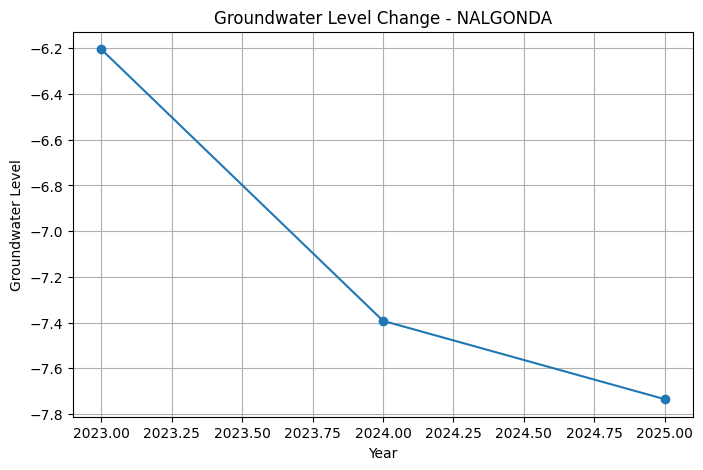

In [ ]:
year_ground = temp.groupby('Year')['Groundwater'].mean()


plt.figure(figsize=(8,5))

plt.plot(year_ground.index,
         year_ground.values,
         marker='o')


plt.title(f"Groundwater Level Change - {location}")

plt.xlabel("Year")
plt.ylabel("Groundwater Level")

plt.grid()

plt.show()

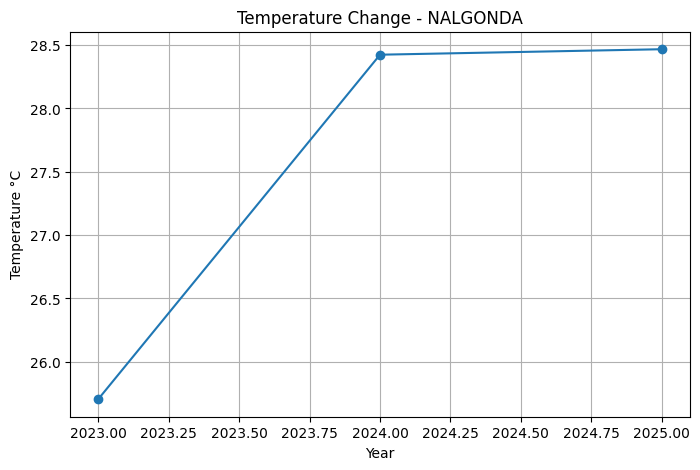

In [ ]:
year_temp = temp.groupby('Year')['Temperature'].mean()


plt.figure(figsize=(8,5))

plt.plot(year_temp.index,
         year_temp.values,
         marker='o')


plt.title(f"Temperature Change - {location}")

plt.xlabel("Year")
plt.ylabel("Temperature °C")

plt.grid()

plt.show()

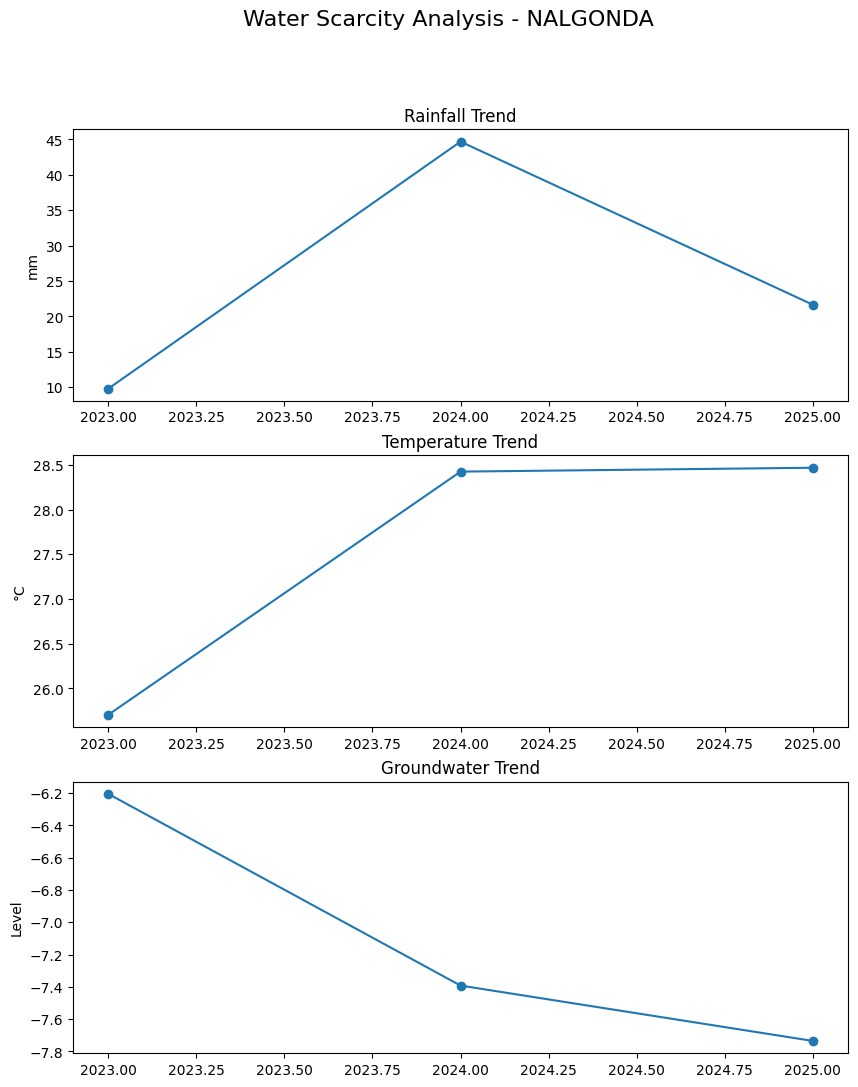

In [ ]:
fig,ax = plt.subplots(3,1,figsize=(10,12))


# Rainfall
ax[0].plot(
    year_rain.index,
    year_rain.values,
    marker='o'
)

ax[0].set_title("Rainfall Trend")
ax[0].set_ylabel("mm")


# Temperature
ax[1].plot(
    year_temp.index,
    year_temp.values,
    marker='o'
)

ax[1].set_title("Temperature Trend")
ax[1].set_ylabel("°C")


# Groundwater
ax[2].plot(
    year_ground.index,
    year_ground.values,
    marker='o'
)

ax[2].set_title("Groundwater Trend")
ax[2].set_ylabel("Level")


plt.suptitle(
f"Water Scarcity Analysis - {location}",
fontsize=16
)

plt.show()

In [ ]:
district_risk = df.groupby('District')['Scarcity_Score'].mean()

district_risk.sort_values()

,Scarcity_Score
District,
BHUPALPALLY,0.581710
MEDAK,0.652449
KAMAREDDY,0.658543
ADILABAD,0.663611
RAJANNA SIRCILLA,0.671304
NIRMAL,0.674318
KUMURAM BHEEM,0.675631
MULUGU,0.693296
PEDDAPALLY,0.696696


In [ ]:
def water_report(place):

    data=df[df['District']==place]

    print("Location:",place)

    print("\nAverage Rainfall:",
          round(data['Rainfall'].mean(),2))

    print("Average Temperature:",
          round(data['Temperature'].mean(),2))

    print("Average Groundwater:",
          round(data['Groundwater'].mean(),2))


    risk=data['Risk'].mode()[0]

    print("\nWater Scarcity Risk:",risk)



water_report("NALGONDA")

Location: NALGONDA

Average Rainfall: 32.59
Average Temperature: 28.29
Average Groundwater: -7.48

Water Scarcity Risk: High


In [ ]:
df['Day'] = pd.to_datetime(df['Day'])

df['Year'] = df['Day'].dt.year

df.head()

,District,Day,Rainfall,Temperature,Groundwater,Rainfall_Norm,Temp_Norm,Groundwater_Norm,Scarcity_Score,Risk,District_encoded,Station,Latitude,Longitude,Year
0,ADILABAD,2023-07-26,1.5,28.533333,-11.280909,0.999938,0.644357,0.439568,0.725152,High,0,Mathadivagu Project,19.682,78.447,2023
1,ADILABAD,2023-07-26,1.5,28.533333,-11.280909,0.999938,0.644357,0.439568,0.725152,High,0,Satnala project,19.644,78.664,2023
2,ADILABAD,2023-07-27,143.5,26.970833,-11.073341,0.991066,0.593890,0.443276,0.707576,High,0,Mathadivagu Project,19.682,78.447,2023
3,ADILABAD,2023-07-27,143.5,26.970833,-11.073341,0.991066,0.593890,0.443276,0.707576,High,0,Satnala project,19.644,78.664,2023
4,ADILABAD,2023-07-28,40.5,27.179167,-10.897773,0.997501,0.600619,0.446412,0.713110,High,0,Mathadivagu Project,19.682,78.447,2023


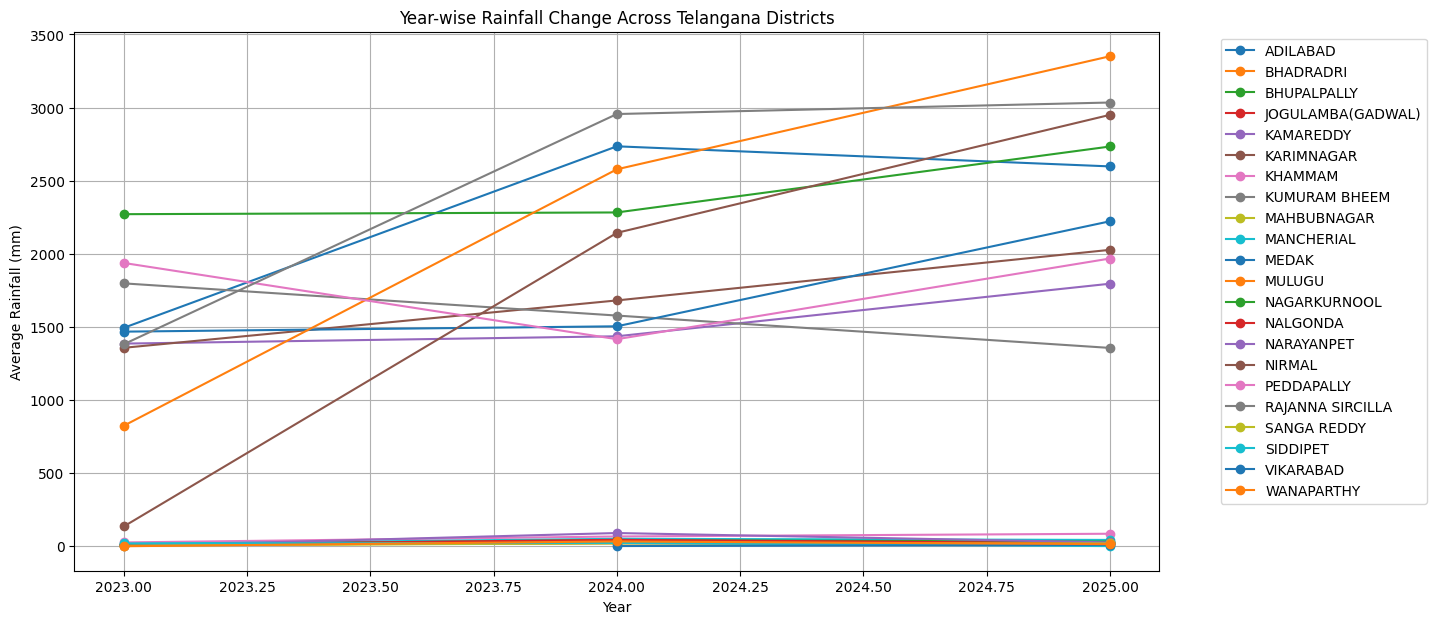

In [ ]:
import matplotlib.pyplot as plt

rain_year = df.groupby(
    ['District','Year']
)['Rainfall'].mean().reset_index()


plt.figure(figsize=(14,7))

for district in rain_year['District'].unique():
    temp = rain_year[rain_year['District']==district]
    plt.plot(
        temp['Year'],
        temp['Rainfall'],
        marker='o',
        label=district
    )

plt.title("Year-wise Rainfall Change Across Telangana Districts")
plt.xlabel("Year")
plt.ylabel("Average Rainfall (mm)")
plt.legend(bbox_to_anchor=(1.05,1))
plt.grid()
plt.show()

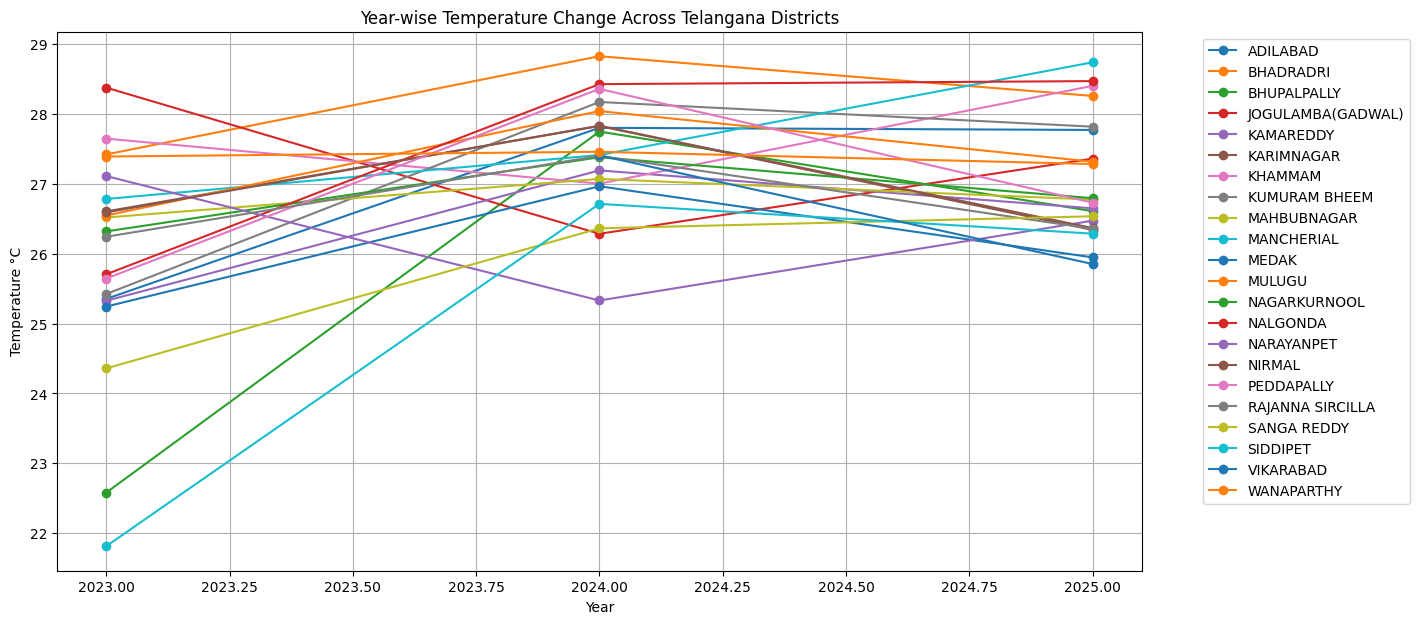

In [ ]:
temp_year = df.groupby(
    ['District','Year']
)['Temperature'].mean().reset_index()


plt.figure(figsize=(14,7))

for district in temp_year['District'].unique():

    temp=temp_year[temp_year['District']==district]

    plt.plot(
        temp['Year'],
        temp['Temperature'],
        marker='o',
        label=district
    )


plt.title("Year-wise Temperature Change Across Telangana Districts")
plt.xlabel("Year")
plt.ylabel("Temperature °C")
plt.legend(bbox_to_anchor=(1.05,1))
plt.grid()

plt.show()

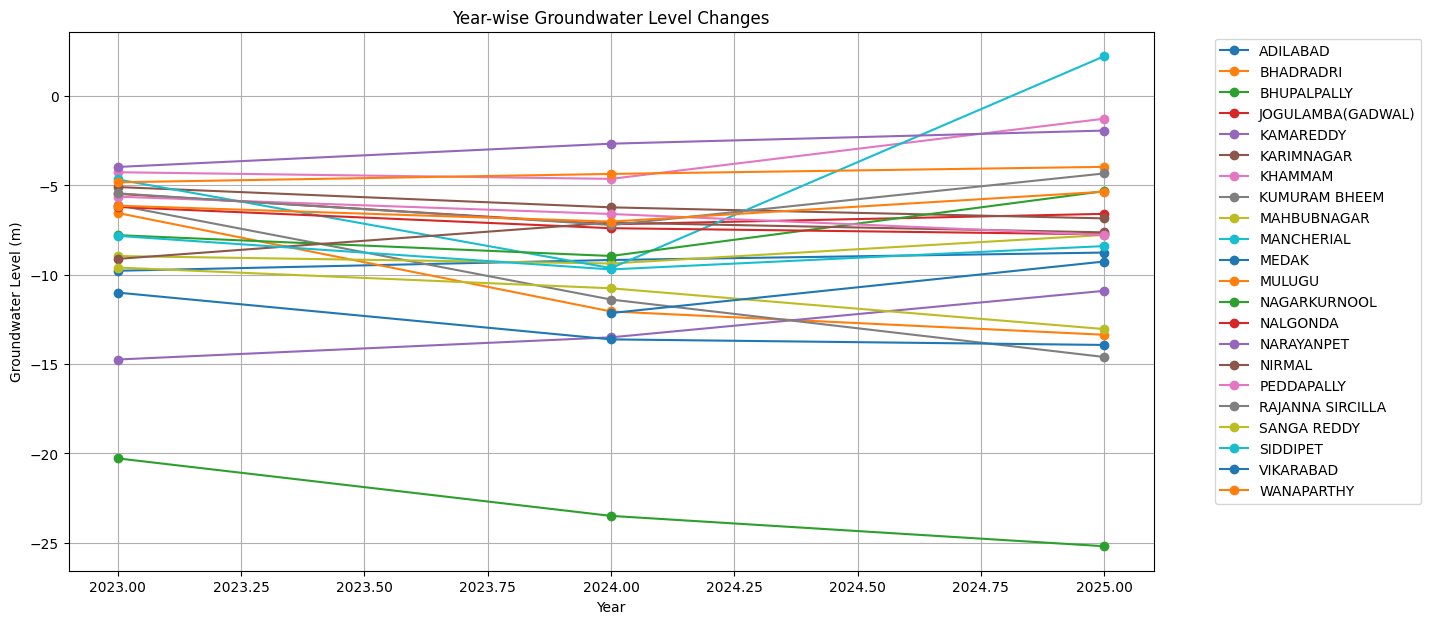

In [ ]:
gw_year = df.groupby(
    ['District','Year']
)['Groundwater'].mean().reset_index()


plt.figure(figsize=(14,7))


for district in gw_year['District'].unique():

    temp=gw_year[gw_year['District']==district]

    plt.plot(
        temp['Year'],
        temp['Groundwater'],
        marker='o',
        label=district
    )


plt.title("Year-wise Groundwater Level Changes")
plt.xlabel("Year")
plt.ylabel("Groundwater Level (m)")
plt.legend(bbox_to_anchor=(1.05,1))
plt.grid()

plt.show()

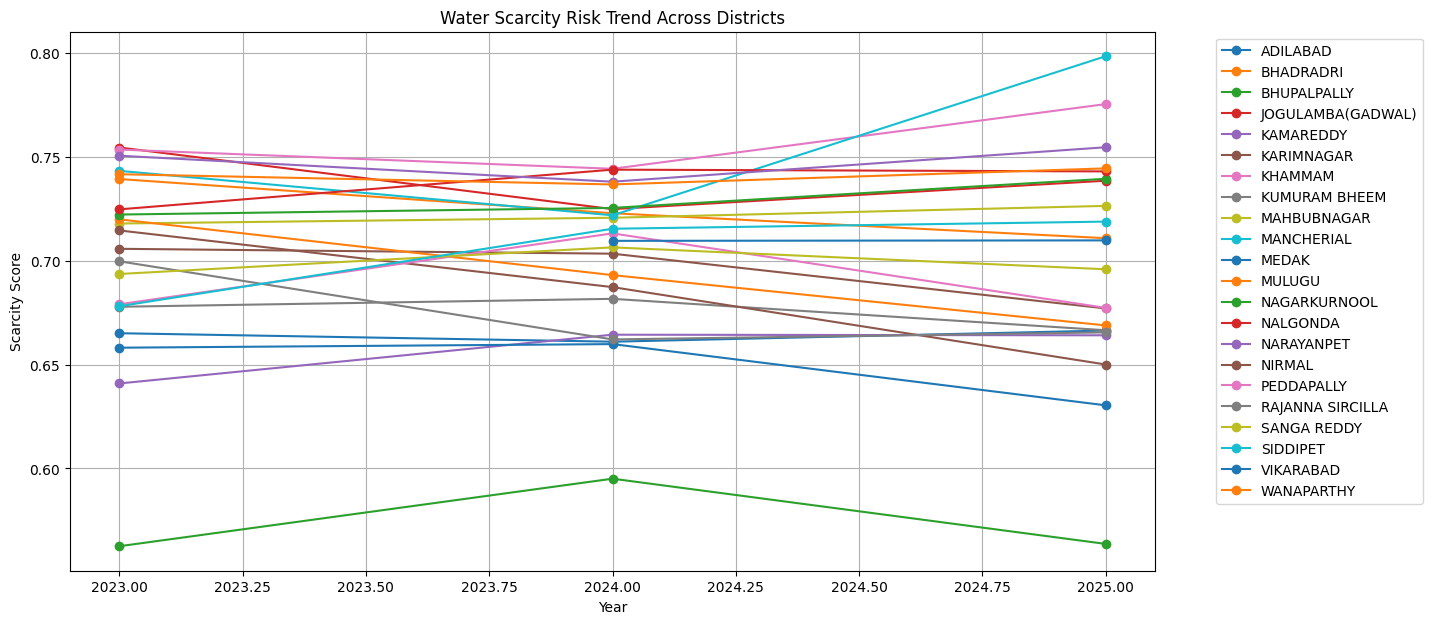

In [ ]:
scarcity_year=df.groupby(
    ['District','Year']
)['Scarcity_Score'].mean().reset_index()


plt.figure(figsize=(14,7))


for district in scarcity_year['District'].unique():

    temp=scarcity_year[
        scarcity_year['District']==district
    ]

    plt.plot(
        temp['Year'],
        temp['Scarcity_Score'],
        marker='o',
        label=district
    )


plt.title("Water Scarcity Risk Trend Across Districts")
plt.xlabel("Year")
plt.ylabel("Scarcity Score")
plt.legend(bbox_to_anchor=(1.05,1))
plt.grid()

plt.show()

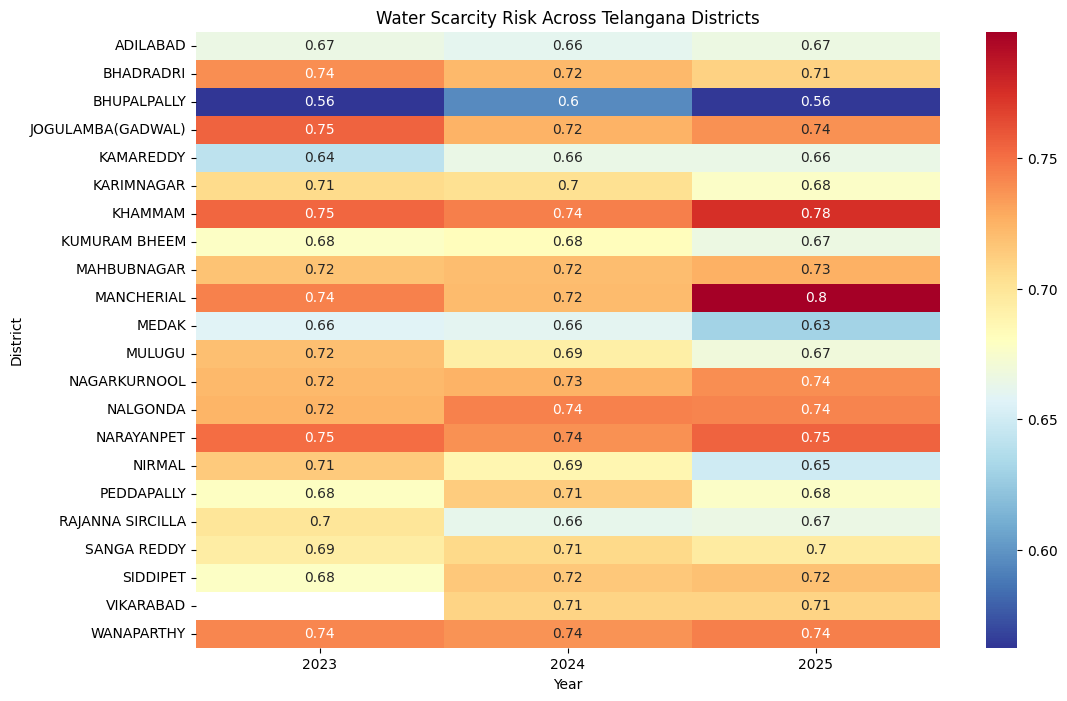

In [ ]:
import seaborn as sns

risk_matrix=df.pivot_table(
    values='Scarcity_Score',
    index='District',
    columns='Year',
    aggfunc='mean'
)


plt.figure(figsize=(12,8))

sns.heatmap(
    risk_matrix,
    cmap="RdYlBu_r",
    annot=True
)

plt.title("Water Scarcity Risk Across Telangana Districts")
plt.xlabel("Year")
plt.ylabel("District")

plt.show()